In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report
)

In [2]:
file_path = r"C:\Users\Keshav Kalani\Desktop\lets do this\practicals\ML Codes\ML dataset\diabetes.csv"
df = pd.read_csv(file_path)

print("Dataset loaded successfully")
print("Rows and columns:", df.shape)
print(df.head())

Dataset loaded successfully
Rows and columns: (768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  


In [3]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Zero values in these measurements may represent missing measurements
measurement_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

print("\nZero values in measurement columns:")
print((df[measurement_columns] == 0).sum())

Missing values in each column:
Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64

Duplicate rows: 0

Zero values in measurement columns:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [4]:
from sklearn.impute import SimpleImputer

measurement_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Treat zero measurements as missing
df[measurement_columns] = df[measurement_columns].replace(0, np.nan)

# Separate features (X) from the target label (y)
X = df.drop(columns=["Outcome"])
y = df["Outcome"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("\nTraining target distribution:")
print(y_train.value_counts())

Training rows: 614
Testing rows: 154

Training target distribution:
Outcome
0    400
1    214
Name: count, dtype: int64


In [5]:
knn_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn_model.fit(X_train, y_train)

y_pred = knn_model.predict(X_test)

print("Predictions made successfully")
print("First 10 predicted outcomes:", y_pred[:10])

Predictions made successfully
First 10 predicted outcomes: [1 0 0 1 0 0 0 1 0 1]


In [6]:
cm = confusion_matrix(y_test, y_pred)

accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)

print("Confusion Matrix:")
print(cm)

print("\nAccuracy:", round(accuracy, 4))
print("Error Rate:", round(error_rate, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))

Confusion Matrix:
[[83 17]
 [21 33]]

Accuracy: 0.7532
Error Rate: 0.2468
Precision: 0.66
Recall: 0.6111


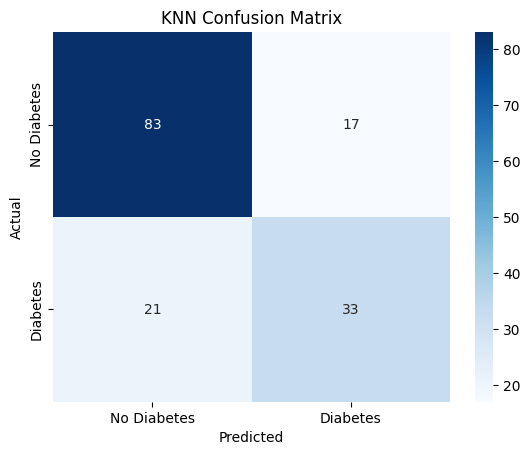

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")
plt.show()

## Practical 5 — Likely Viva Questions and Answers

1. **What is the aim of this practical?**  
   To use K-Nearest Neighbors (KNN) to predict whether a patient has diabetes, then evaluate the model.

2. **What is the target column?**  
   `Outcome`: `1` means diabetes and `0` means no diabetes.

3. **What are the input features?**  
   Patient measurements such as glucose, blood pressure, BMI, age, and pregnancies.

4. **What type of machine-learning task is this?**  
   Binary classification, because the model chooses between two classes.

5. **What is KNN?**  
   A method that classifies a new record based on the classes of its nearest records in the training data.

6. **What does `n_neighbors=5` mean?**  
   The model considers the five nearest training records to decide the predicted class.

7. **How does KNN decide the class?**  
   It chooses the class that appears most often among the nearest neighbors.

8. **Why is feature scaling used for KNN?**  
   KNN uses distances, so scaling prevents large-valued features from overpowering smaller-valued features.

9. **Why were zero values in some measurements treated as missing?**  
   In this dataset, zero values for glucose, blood pressure, skin thickness, insulin, or BMI may mean the measurement was not recorded.

10. **How were those missing measurements filled?**  
    With the median of each feature, learned from the training data.

11. **Why split data into training and testing sets?**  
    The model learns from the training data and is evaluated on separate data it did not train on.

12. **What is a confusion matrix?**  
    A table comparing actual classes with predicted classes, showing correct and incorrect predictions.

13. **What is accuracy?**  
    The fraction of all predictions that were correct.

14. **What is error rate?**  
    The fraction of predictions that were incorrect. It is calculated as \(1-\text{accuracy}\).

15. **What is precision?**  
    Of the records predicted as diabetes, the fraction that actually have diabetes.

16. **What is recall?**  
    Of all patients who actually have diabetes, the fraction the model correctly identified.

17. **Why might recall matter in diabetes prediction?**  
    Low recall means the model misses more patients who actually have diabetes.

18. **What happens if the value of K is too small?**  
    The model can be overly affected by noise or individual records.

19. **What happens if the value of K is too large?**  
    The model may be less sensitive to local patterns and may favor the more common class.

20. **Why use the median to fill missing values?**  
    The median is less affected by extreme values than the mean.